## Radial dose function fit sandbox

In [48]:
# Allows Python to find mosh_src if this notebook is moved
import sys
sys.path.insert(0, "/Users/seanmullane/Desktop/Research_2025/modulated_shielding")

# Add functionality to parse folders
import os

# Import matplotlib and numpy - helpful Python libraries for scientific computing
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.patches as patches
from matplotlib import ticker
from math import pi
from decimal import Decimal

from scipy.optimize import curve_fit
from scipy.interpolate import RegularGridInterpolator
from scipy.interpolate import CubicSpline

# Import all MOSH plotting functions
from mosh_src.plotting_functions import *

In [2]:
# Import data
g_data = np.genfromtxt("g_L_data.txt")
r = g_data[:,0]
g_value = g_data[:,1]

### Scipy curve_fit() method

In [36]:
# trying an oscillatory fit first
def F_osc(x, a, b, c, d, e, f):
    return a + b*x + c*np.sin(d*x) + e*np.cos(f*x)

# also trying 5th degree polynomial fit, which seems to be recommended by TG-43?
#def F_osc(x, a1, a2, a3, a4, a5, a6):
    #return a1 + a2*x + a3*x**2 + a4*x**3 + a5*x**4 + a6*x**5

popt, pcov = curve_fit(F_osc, r, g_value)
#popt, pcov = curve_fit(F_5, r, g_value)
# check condition number of covariance matrix
print(popt)
print(np.sum(popt))
print(np.linalg.cond(pcov))
print(np.diag(pcov))

[ 0.99324115 -0.0039364   0.02834715  0.37289559 -0.00213786  1.26642282]
2.654832442206191
768702.9839551105
[2.37023741e-07 5.90689259e-08 8.25152606e-07 8.50429163e-05
 1.37921742e-07 1.87802982e-03]


0.0611801999177563
0.9989912930406771


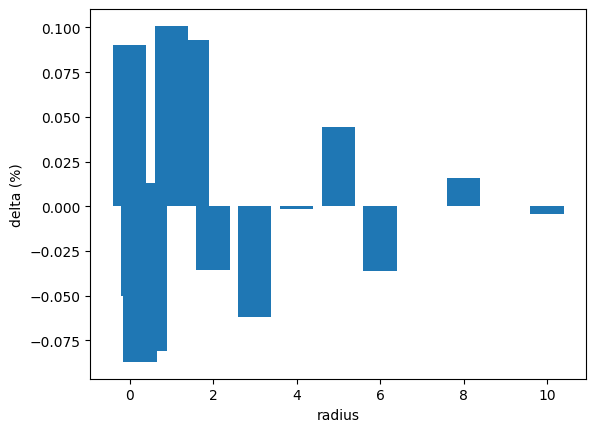

In [38]:
test_data_scipy = F_osc(r, *popt)
residual = ((g_value - test_data_scipy)/g_value)*100

# calculate RMSE
rmse = np.sqrt(np.mean(residual**2))
print(rmse)

# compute g(r_0 = 1.0 cm) with our model
print(F_osc(1.0, *popt)) # should check this later - does it need to be exactly 1.0000 per one of the TG-43 documents?

# plot for debugging
fig2, ax2 = plt.subplots()
ax2.bar(r, residual)
ax2.set_xlabel('radius')
ax2.set_ylabel('delta (%)')
plt.show()

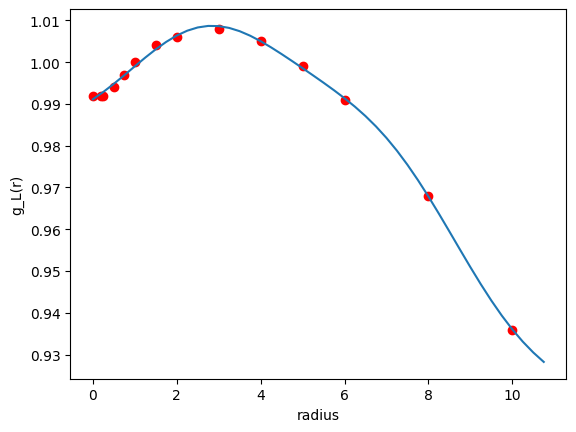

In [39]:
# plot original function values vs predicted with model above
r_fine = np.arange(0, 11, 0.25)

fig3, ax3 = plt.subplots()
ax3.scatter(r, g_value, color='red')
ax3.plot(r_fine, F_osc(r_fine, *popt))
ax3.set_xlabel('radius')
ax3.set_ylabel('g_L(r)')
plt.show()

# this looks pretty good!

### Scipy interp() method

In [46]:
# evaluate over the range r_fine defined above
r_fine = np.arange(0, 11, 0.05)
g_interp = np.interp(r_fine, r, g_value) # piecewise linear - probably not good enough for our purposes

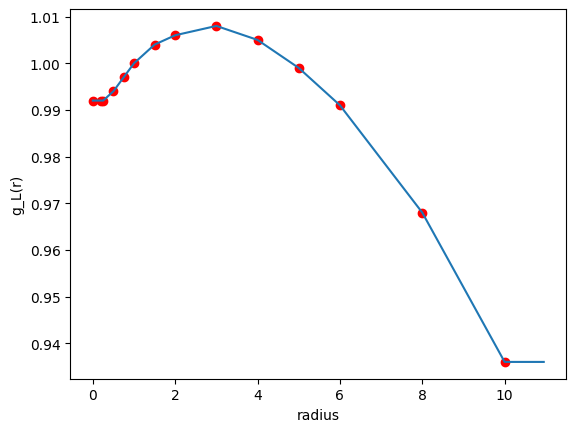

In [47]:
# plot the interpolation
fig4, ax4 = plt.subplots()
ax4.scatter(r, g_value, color='red')
ax4.plot(r_fine, g_interp)
ax4.set_xlabel('radius')
ax4.set_ylabel('g_L(r)')
plt.show()

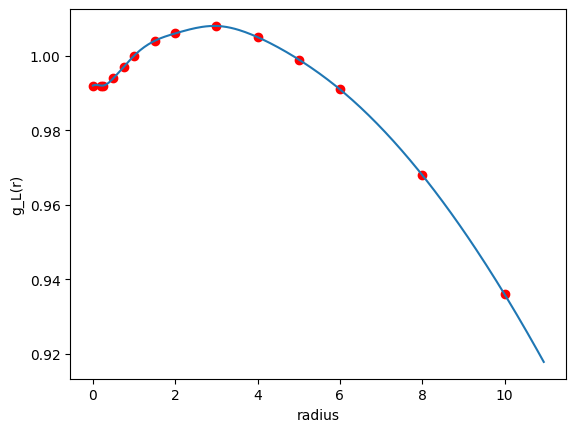

In [51]:
# let's try cubic spline, which is continuous up the second derivative
g_cs = CubicSpline(r, g_value)

fig5, ax5 = plt.subplots()
ax5.scatter(r, g_value, color='red')
ax5.plot(r_fine, g_cs(r_fine))
ax5.set_xlabel('radius')
ax5.set_ylabel('g_L(r)')
plt.show()